C:\Users\kuroc\AppData\Local\Programs\Python\Python312\Lib\site-packages\gym\utils\passive_env_checker.py:246: DeprecationWarning: `np.bool8` is a deprecated alias for `np.bool_`.  (Deprecated NumPy 1.24)
  if not isinstance(done, (bool, np.bool8)):


[Episode   1] Reward:  -20.0 | Epsilon:  0.995
[Episode   2] Reward:  -20.0 | Epsilon:  0.990
[Episode   3] Reward:  -20.0 | Epsilon:  0.985
[Episode   4] Reward:  -20.0 | Epsilon:  0.980
[Episode   5] Reward:  -20.0 | Epsilon:  0.975
[Episode   6] Reward:  -20.0 | Epsilon:  0.970
[Episode   7] Reward:  -20.0 | Epsilon:  0.966
[Episode   8] Reward:  -20.0 | Epsilon:  0.961
[Episode   9] Reward:  -20.0 | Epsilon:  0.956
[Episode  10] Reward:  -20.0 | Epsilon:  0.951
[Episode  11] Reward:  -20.0 | Epsilon:  0.946
[Episode  12] Reward:  -20.0 | Epsilon:  0.942
[Episode  13] Reward:  -20.0 | Epsilon:  0.937
[Episode  14] Reward:  -20.0 | Epsilon:  0.932
[Episode  15] Reward:  -20.0 | Epsilon:  0.928
[Episode  16] Reward:  -20.0 | Epsilon:  0.923
[Episode  17] Reward:  -20.0 | Epsilon:  0.918
[Episode  18] Reward:  -20.0 | Epsilon:  0.914
[Episode  19] Reward:  -20.0 | Epsilon:  0.909
[Episode  20] Reward:  -20.0 | Epsilon:  0.905
[Episode  21] Reward:  -20.0 | Epsilon:  0.900
[Episode  22]

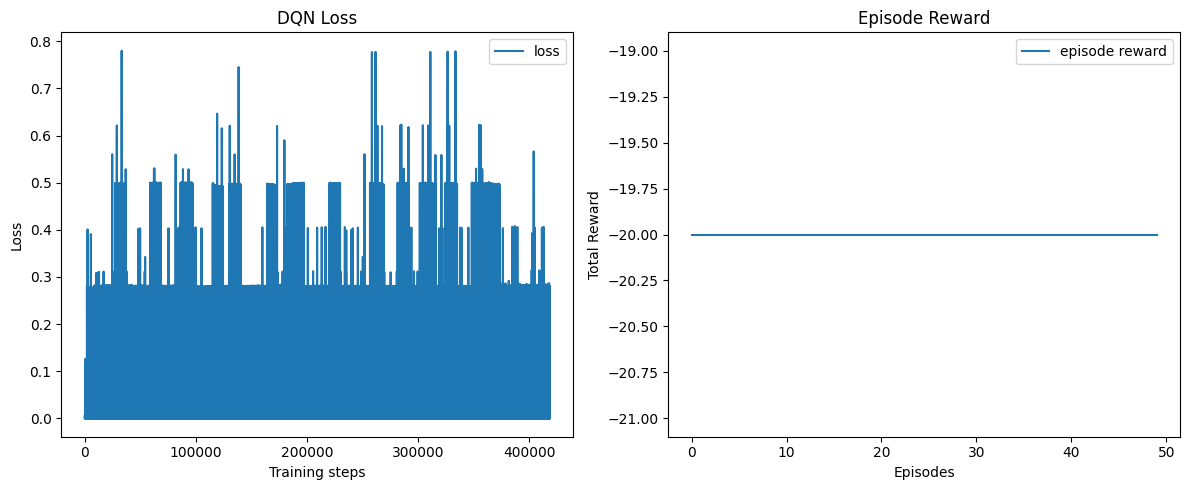

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
from collections import deque
import cv2

import torch
import torch.nn as nn
import torch.optim as optim

from nes_py.wrappers import JoypadSpace
import gym_tetris
from gym_tetris.actions import MOVEMENT

# --------------------------
# 전처리 함수 정의
# --------------------------
def preprocess_state(state):
    """
    NES Tetris에서 받은 원본 상태(state)는 (240, 256, 3) 형태의 RGB 이미지.
    1) Grayscale 변환
    2) (84, 84)로 리사이즈
    3) [0, 1] 정규화
    4) Flatten (1D 벡터화)
    """
    # 1. 흑백 변환
    gray = cv2.cvtColor(state, cv2.COLOR_RGB2GRAY)  # (240, 256)

    # 2. (84, 84)로 리사이즈
    resized = cv2.resize(gray, (84, 84), interpolation=cv2.INTER_AREA)  # (84, 84)

    # 3. [0, 1] 범위로 정규화
    normalized = resized / 255.0

    # 4. flatten
    # 최종 shape: (84*84, ) = (7056, )
    flattened = normalized.reshape(-1)

    return flattened.astype(np.float32)


# --------------------------
# 하이퍼파라미터 정의
# --------------------------
EPISODES = 50           # 학습 에피소드 수
MEMORY_SIZE = 10000     # 리플레이 버퍼 크기
BATCH_SIZE = 32
GAMMA = 0.99            # 할인율
LR = 1e-4               # 학습률
EPS_START = 1.0         # e-greedy 탐험 초기값
EPS_END = 0.01          # e-greedy 탐험 최소값
EPS_DECAY = 0.995       # 에피소드마다 epsilon을 곱해줄 비율
TARGET_UPDATE = 5       # target 네트워크 업데이트 주기


# --------------------------
# DQN 신경망
# --------------------------
class DQN(nn.Module):
    def __init__(self, input_size, action_size):
        super(DQN, self).__init__()
        hidden = 256
        self.net = nn.Sequential(
            nn.Linear(input_size, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, action_size)
        )

    def forward(self, x):
        return self.net(x)


# --------------------------
# Replay Buffer 정의
# --------------------------
class ReplayBuffer:
    def __init__(self, capacity):
        self.buffer = deque(maxlen=capacity)
    
    def push(self, state, action, reward, next_state, done):
        self.buffer.append((state, action, reward, next_state, done))
    
    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)
        states, actions, rewards, next_states, dones = zip(*batch)
        return (np.array(states, dtype=np.float32),
                np.array(actions, dtype=np.int64),
                np.array(rewards, dtype=np.float32),
                np.array(next_states, dtype=np.float32),
                np.array(dones, dtype=np.float32))
    
    def __len__(self):
        return len(self.buffer)


# --------------------------
# Epsilon-greedy로 행동 선택
# --------------------------
def select_action(state, policy_net, epsilon, action_size, device):
    if random.random() < epsilon:
        # 무작위 행동
        return random.randint(0, action_size - 1)
    else:
        # Q값이 가장 큰 행동
        state_t = torch.FloatTensor(state).unsqueeze(0).to(device)  # shape: (1, input_size)
        q_values = policy_net(state_t)  # shape: (1, action_size)
        _, action = torch.max(q_values, dim=1)
        return action.item()


# --------------------------
# 미니배치 학습 함수
# --------------------------
def train_step(policy_net, target_net, optimizer, replay_buffer, device):
    if len(replay_buffer) < BATCH_SIZE:
        return None  # 버퍼가 충분히 차지 않았으면 학습 X

    states, actions, rewards, next_states, dones = replay_buffer.sample(BATCH_SIZE)

    # Tensor 변환
    states_t = torch.FloatTensor(states).to(device)         # (B, input_size)
    actions_t = torch.LongTensor(actions).to(device).unsqueeze(1)  # (B, 1)
    rewards_t = torch.FloatTensor(rewards).to(device).unsqueeze(1) # (B, 1)
    next_states_t = torch.FloatTensor(next_states).to(device)       # (B, input_size)
    dones_t = torch.FloatTensor(dones).to(device).unsqueeze(1)      # (B, 1)

    # 현재 Q(s,a) 계산
    q_values = policy_net(states_t).gather(1, actions_t)

    # 최대 Q(s',a') (next_state에 대한) 계산 (target_net 사용)
    with torch.no_grad():
        max_next_q_values = target_net(next_states_t).max(dim=1, keepdim=True)[0]
        # 벨만 식
        target_q_values = rewards_t + GAMMA * max_next_q_values * (1 - dones_t)

    # MSE 손실 계산
    loss = nn.MSELoss()(q_values, target_q_values)

    # 역전파 & 업데이트
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    return loss.item()


# --------------------------
# 메인 학습 루프
# --------------------------
def main():
    # (1) 환경 설정
    env = gym_tetris.make('TetrisA-v3')
    env = JoypadSpace(env, MOVEMENT)
    
    # 한 번 reset해서 원본 state 얻은 뒤, 전처리 후 shape 확인
    sample_state = env.reset()
    pre_sample = preprocess_state(sample_state)  # shape -> (7056, )
    input_size = pre_sample.shape[0]            # 7056
    action_size = env.action_space.n

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # (2) DQN 네트워크 생성
    policy_net = DQN(input_size, action_size).to(device)
    target_net = DQN(input_size, action_size).to(device)
    target_net.load_state_dict(policy_net.state_dict())
    target_net.eval()

    optimizer = optim.Adam(policy_net.parameters(), lr=LR)
    replay_buffer = ReplayBuffer(MEMORY_SIZE)

    epsilon = EPS_START

    # 학습 기록 (loss, reward)
    losses = []
    episode_rewards = []

    for ep in range(EPISODES):
        # 에피소드 시작 시 상태 초기화 & 전처리
        state_raw = env.reset()                  # 원본 (240,256,3)
        state = preprocess_state(state_raw)      # (7056, )
        done = False
        total_reward = 0

        while not done:
            # e-greedy로 행동 선택
            action = select_action(state, policy_net, epsilon, action_size, device)

            # 환경에서 한 스텝 진행
            next_state_raw, reward, done, info = env.step(action)
            next_state = preprocess_state(next_state_raw)

            total_reward += reward

            # 리플레이 버퍼에 저장
            replay_buffer.push(state, action, reward, next_state, done)

            # 상태 업데이트
            state = next_state

            # 학습(미니배치 업데이트)
            loss_val = train_step(policy_net, target_net, optimizer, replay_buffer, device)
            if loss_val is not None:
                losses.append(loss_val)

        # 에피소드가 끝나면 epsilon 감소
        epsilon = max(EPS_END, epsilon * EPS_DECAY)
        episode_rewards.append(total_reward)

        # 일정 주기마다 타겟 네트워크 업데이트
        if ep % TARGET_UPDATE == 0:
            target_net.load_state_dict(policy_net.state_dict())

        print(f"[Episode {ep+1:3d}] Reward: {total_reward:6.1f} | Epsilon: {epsilon: .3f}")

    # ---------------------------
    # 7. 학습 결과(loss) 시각화
    # ---------------------------
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(losses, label='loss')
    plt.xlabel('Training steps')
    plt.ylabel('Loss')
    plt.title('DQN Loss')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(episode_rewards, label='episode reward')
    plt.xlabel('Episodes')
    plt.ylabel('Total Reward')
    plt.title('Episode Reward')
    plt.legend()

    plt.tight_layout()
    plt.show()

    env.close()


if __name__ == "__main__":
    main()
